# 01 · Historical price gaps between Kalshi and Polymarket

This notebook asks whether the same event had **different prices on Kalshi and
Polymarket**, hour by hour over the whole history of our 155 verified pairs
(November 2024 to November 2026), and whether those differences were **real
arbitrage opportunities after fees**.

| part | question |
|---|---|
| 1 | Align both venues on one hourly UTC grid |
| 2 | How large is the gap: raw, and as an executable trade after fees? |
| 3 | How often is there a profitable gap, by topic and by time to resolution? |
| 4 | How long does a gap last? (AR(1) and half-life) |
| 5 | What makes gaps large? (regression, clustered by pair) |
| 6 | Which venue moves first? (Granger causality) |
| 7 | How much does it cost when "the same" market pays differently? |
| 8 | Figures and the results table (`figures/`, `docs/results.md`) |

**Data** (all in `data/processed/`): `pairs.parquet` (the 155 verified pairs,
see `docs/matching.md`), `kalshi_candles.parquet` (Kalshi's hourly candles),
`poly_trade_bars.parquet` (Polymarket trades in 1-hour bars, see
`docs/poly_trades.md`), `poly_prices.parquet` (Polymarket's own price history,
only as a cross-check), `poly_orderbooks.parquet` (to estimate Polymarket's
spread), `poly_markets.parquet` (Polymarket's fee fields) and
`match_verified.csv` (all 201 candidate pairs, for part 7). The fee formulas
come from `src/arb.py` (see `docs/arbitrage.md`); the alignment and gap
formulas are in `src/gaps.py`, with unit tests in `tests/test_gaps.py`.

**Conventions.** All times are UTC. Prices are in dollars between 0 and 1 (a
price of 0.42 is 42 cents, and the market's probability of 42%). Gaps are
shown in **cents** where that is easier to read; the tables say so.

**How to run it again** (from the project folder, about a minute):

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/01_historical_gaps.ipynb
```

In [1]:
# Setup: find the project folder, let Python import our code in src/, load the packages.
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
import arb       # the two venues' fee formulas (src/arb.py)
import gaps      # alignment and gap formulas (src/gaps.py)
import kalshi    # only for save_table(), which refuses files of 50 MB or more

DATA = PROJECT / "data" / "processed"
FIGURES = PROJECT / "figures"
DOCS = PROJECT / "docs"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Every table that goes into docs/results.md is collected here (part 8 writes the file).
RESULTS = {}

pairs = pd.read_parquet(DATA / "pairs.parquet")
candles = pd.read_parquet(DATA / "kalshi_candles.parquet")
trade_bars = pd.read_parquet(DATA / "poly_trade_bars.parquet")
poly_prices = pd.read_parquet(DATA / "poly_prices.parquet")
poly_markets = pd.read_parquet(DATA / "poly_markets.parquet")
print(f"{len(pairs)} pairs; {len(candles):,} Kalshi candles; {len(trade_bars):,} Polymarket trade bars; "
      f"{len(poly_prices):,} Polymarket price points")

155 pairs; 1,837,894 Kalshi candles; 203,638 Polymarket trade bars; 607,341 Polymarket price points


## 1. One hourly grid for both venues

We build one table with **one row per pair and hour**. Each row says what both
venues' prices were at the end of that hour (`bar_end`, UTC). Kalshi labels its
hourly candles by their end, and so do our Polymarket trade bars, so the two
are joined on `bar_end`.

**Which hours.** A pair's rows start at the first hour in which *both* venues
have a price and end at the last full hour *before Kalshi closes*. Kalshi
closes just before the news (one minute before the 8:30 AM ET CPI release, a
few minutes before the Fed's 2 PM ET statement). The hour that contains the
close is left out on purpose: in it, Polymarket already trades on the news
while Kalshi's last quote is from before the news, and the "gap" would only
measure who was still open. For pairs that are still open, the rows end at the
hour of the Kalshi download (2026-11-04 16:00 UTC).

**Kalshi: carry the last candle forward, without a time limit.** Kalshi sends
a candle only for an hour in which something changed (a trade, or a new best
bid or ask). An hour without a candle therefore had the *same* quotes as the
last candle, however long ago that was. We take the bid, the ask and the last
traded price from the last candle at or before each hour.
- **An empty quote stays empty.** If the last candle has no bid (nobody was
  bidding), the bid is empty, even if there was a bid a week earlier. Filling
  in the old bid would invent a price nobody offered.
- **Kalshi's mid** = (bid + ask) / 2, only when both exist.

**Polymarket: the last trade, with its age.** Polymarket's history has trades,
but no bid and ask. In each hour we take the *latest trade of either token*,
YES or NO, and carry it forward through hours without trades. The YES and NO
token are two views of one market: together they pay exactly $1, so a NO
trade at 0.30 says the same as a YES trade at 0.70. For every hour we record
**how old** the price is (`poly_age_hours`). **Prices older than 24 hours are
left out of all main results**: a trade from two days ago is not what traders
thought in this hour. The rows stay in the table with their age, so the
cut-off can be changed.

**Matching sides.** The pair's `poly_yes_equals` column says whether
Polymarket's YES is the same outcome as Kalshi's YES ("Kalshi YES", 116 pairs)
or as Kalshi's NO ("Kalshi NO", 39 pairs). Every Polymarket price is turned
into the price of *the token that pays when Kalshi's YES pays*, so the two
venues' numbers mean the same thing (`gaps.poly_in_kalshi_yes_terms()`).

In [2]:
# Only the candles of our 155 Kalshi markets are needed.
pair_candles = candles[candles["ticker"].isin(pairs["kalshi_ticker"])]
DATA_END = pair_candles["period_end"].max()          # the hour of the Kalshi download
panel = gaps.build_panel(pairs, pair_candles, trade_bars, data_end=DATA_END)
panel["kalshi_mid"] = gaps.kalshi_mid(panel["kalshi_bid"], panel["kalshi_ask"])
print(f"Last hour of data for open pairs: {DATA_END:%Y-%m-%d %H:%M} UTC")
print(f"{len(panel):,} pair-hours for {panel['pair_id'].nunique()} pairs")

TOPICS = ["Fed", "CPI MoM", "CPI YoY"]
coverage = panel.groupby("topic").agg(
    pairs=("pair_id", "nunique"),
    pair_hours=("bar_end", "size"),
    first_hour=("bar_end", "min"),
    last_hour=("bar_end", "max"),
    kalshi_bid_and_ask=("kalshi_mid", lambda s: s.notna().mean()),
    poly_price_at_most_24h_old=("poly_fresh", "mean"),
    both=("kalshi_mid", lambda s: (s.notna() & panel.loc[s.index, "poly_fresh"]).mean()),
).reindex(TOPICS)
coverage["first_hour"] = coverage["first_hour"].dt.strftime("%Y-%m-%d")
coverage["last_hour"] = coverage["last_hour"].dt.strftime("%Y-%m-%d")
display(coverage.round(3))

Last hour of data for open pairs: 2026-11-04 16:00 UTC
220,609 pair-hours for 155 pairs


,pairs,pair_hours,first_hour,last_hour,kalshi_bid_and_ask,poly_price_at_most_24h_old,both
topic,,,,,,,
Fed,76,164028,2024-09-17,2026-11-04,0.796,0.947,0.756
CPI MoM,37,24416,2025-01-13,2026-11-04,0.734,0.893,0.689
CPI YoY,42,32165,2024-10-10,2026-10-14,0.711,0.925,0.686


The last three columns are shares of the pair-hours. Kalshi has both a bid and
an ask in most hours. The hours without are outcomes that are almost decided:
Fed buckets that are nearly impossible (nobody bids; the ask is 1 cent in the
median such hour) and CPI outcomes that are nearly certain (nobody sells YES;
the bid is 98 cents in the median such hour). *Both* = the share of hours that
can enter the main results (a Kalshi mid and a Polymarket price at most 24
hours old).

How old is the Polymarket price? The table shows the share of pair-hours in
each age band. Fed markets trade almost every hour; CPI markets are thinner.

In [3]:
age_bands = pd.cut(panel["poly_age_hours"], [0, 1, 6, 24, np.inf],
                   labels=["under 1 h", "1-6 h", "6-24 h", "over 24 h (left out)"])
age_table = pd.crosstab(panel["topic"], age_bands, normalize="index").reindex(TOPICS)
age_table["median age (h)"] = panel.groupby("topic")["poly_age_hours"].median()
display(age_table.round(3))
RESULTS["coverage"] = coverage.join(age_table[["under 1 h", "over 24 h (left out)"]])

# Which token the price comes from (the latest trade in the hour, YES or NO).
print("Share of pair-hours whose Polymarket price comes from each token:")
print(panel["poly_token"].value_counts(normalize=True).round(3).to_string())

poly_age_hours,under 1 h,1-6 h,6-24 h,over 24 h (left out),median age (h)
topic,,,,,
Fed,0.594,0.241,0.111,0.053,0.530
CPI MoM,0.266,0.373,0.254,0.107,3.247
CPI YoY,0.349,0.398,0.179,0.075,1.979


Share of pair-hours whose Polymarket price comes from each token:
poly_token
yes    0.529
no     0.471


### Cross-check with Polymarket's own price history

`poly_prices.parquet` is Polymarket's own price series (one point per 3-hour
bucket over each market's whole life). We do **not** use it for the results:
the API does not say exactly what its price is (a last trade or a midpoint)
or which moment inside the bucket it describes. It is still a useful check
that our trade bars are right. We drop its `point_type = "settlement"` rows,
which are the final payout (1 or 0), not a price, and compare each point with
our trade-bar price (when that is at most 24 hours old) at the bucket's start
and at its end.

In [4]:
check = gaps.poly_prices_cross_check(panel, poly_prices, pairs)
check = check[(check["age_at_start"] <= gaps.MAX_POLY_AGE_HOURS) & (check["age_at_end"] <= gaps.MAX_POLY_AGE_HOURS)]
rows = {}
for label, column in [("our price at the bucket's start", "trade_price_at_start"),
                      ("our price at the bucket's end", "trade_price_at_end")]:
    difference = (check[column] - check["prices_price"]).abs()
    rows[label] = {"points": len(check),
                   "correlation": check[column].corr(check["prices_price"]),
                   "median |difference| (cents)": 100 * difference.median(),
                   "share within 1 cent": (difference <= 0.01).mean(),
                   "share more than 5 cents apart": (difference > 0.05).mean()}
cross_check = pd.DataFrame(rows).T
display(cross_check.round(4))
RESULTS["cross_check"] = cross_check

,points,correlation,median |difference| (cents),share within 1 cent,share more than 5 cents apart
our price at the bucket's start,29180.0,0.9993,0.45,0.8778,0.0062
our price at the bucket's end,29180.0,0.9988,0.50,0.8068,0.0148


The two series agree closely (correlation above 0.99), and best when the
bucket's price is read as the price at the bucket's **start**. The typical
difference of about half a cent is what one would expect if Polymarket's series
were a midpoint: a last trade sits on the bid or the ask, half a spread away
from the mid (part 2 uses this half spread). So the trade bars are a sound
basis for the rest of the notebook.

We save the aligned table, so later notebooks can start from it.

In [5]:
path = kalshi.save_table(panel, "hourly_panel")
print(f"Saved {len(panel):,} rows to {path.relative_to(PROJECT)} ({path.stat().st_size / 1e6:.1f} MB)")

Saved 220,609 rows to data/processed/hourly_panel.parquet (4.0 MB)


## 2. Gaps: raw, and as an executable trade after fees

**Raw gap** = Polymarket's last trade − Kalshi's mid, both as the price of
"Kalshi's YES outcome happens". A raw gap of +3 cents means Polymarket thinks
that outcome is 3 percentage points more likely than Kalshi does. The raw gap
is a *disagreement* between the venues, not a profit: nobody can buy at the
mid or at someone else's last trade, and both venues charge fees.

**Executable-style gap.** To lock in a profit you buy two contracts that
together always pay exactly $1, and you buy each at the price someone is
asking for it (`docs/arbitrage.md`). There are two ways to do this:

| direction | Kalshi leg (real quote from the candle) | Polymarket leg (estimated) |
|---|---|---|
| "yes" | buy Kalshi YES at Kalshi's **ask** | buy the token that pays when Kalshi YES fails, at (1 − Polymarket price) + **half spread** |
| "no" | buy Kalshi NO at 1 − Kalshi's YES **bid** | buy the token that pays when Kalshi YES happens, at Polymarket price + **half spread** |

For each direction, per contract: *gross* = 1 − Kalshi cost − Polymarket cost,
and *net* = gross − Kalshi fee − Polymarket fee. The executable-style gap is
the net of the better direction (`gaps.executable_gaps()`). Only one direction
can make money: the two gross gaps add up to minus both venues' spreads.

**Why half a spread.** Polymarket's history has no bid and ask, only trades.
A trade happens at the bid (someone sells) or at the ask (someone buys), so on
average a last trade sits in the middle of the spread, and buying costs about
half a spread more. We estimate the typical spread from the order-book data
we have: the 22 paired Polymarket markets that were open in the order-book
snapshot of 2026-11-04 (`poly_orderbooks.parquet`).

**Fees, as in force at each hour** (`src/arb.py`, formulas and sources in
`docs/arbitrage.md`):
- *Kalshi*: 0.07 × P × (1 − P) per contract at the price P paid, times the
  series' multiplier (1 for all our series). Kalshi's fee-change history has no
  change for our series, so the same formula applies at every hour.
- *Polymarket*: each market's own fee rate × p × (1 − p) at the price p paid,
  but **zero before 30 March 2026** (Fee Structure V2 brought fees to
  economics markets) and zero for markets without a fee schedule.
- Fees are per contract before rounding; for an order of many contracts,
  Kalshi's rounding adds less than $0.0001 per order.

**The main sample** = the pair-hours in which Kalshi has both a bid and an ask
and Polymarket's price is at most 24 hours old.

In [6]:
TYPICAL_SPREAD, open_spreads = gaps.typical_spread(pd.read_parquet(DATA / "poly_orderbooks.parquet"),
                                                   pairs["poly_market_id"])
HALF_SPREAD = round(TYPICAL_SPREAD / 2, 6)
print(f"Polymarket bid-ask spread in the {len(open_spreads)} open paired markets (2026-11-04 19:42 UTC):")
print(f"   median {TYPICAL_SPREAD:.3f}, mean {open_spreads.mean():.4f}, "
      f"quartiles {open_spreads.quantile(0.25):.4f} and {open_spreads.quantile(0.75):.4f}, "
      f"min {open_spreads.min():.3f}, max {open_spreads.max():.3f}")
print(f"   {(open_spreads < 0.0095).sum()} markets below 1 cent, {((open_spreads >= 0.0095) & (open_spreads <= 0.0105)).sum()} "
      f"at exactly 1 cent, {(open_spreads > 0.0105).sum()} above")
print(f"=> half spread used for every Polymarket purchase: ${HALF_SPREAD:.4f} ({100 * HALF_SPREAD:.2f} cents)")

Polymarket bid-ask spread in the 22 open paired markets (2026-11-04 19:42 UTC):
   median 0.010, mean 0.0120, quartiles 0.0013 and 0.0100, min 0.001, max 0.060
   10 markets below 1 cent, 7 at exactly 1 cent, 5 above
=> half spread used for every Polymarket purchase: $0.0050 (0.50 cents)


**The number: a typical spread of 1 cent, so Polymarket's ask is estimated as
the last trade + 0.5 cents.** The markets with less than a cent are priced near
0, where Polymarket's tick is a tenth of a cent; the widest are thin long-dated
buckets. Two checks agree: the three example pairs in `arb_examples.parquet`
had spreads of 1 to 2 cents, and part 1 found trade prices about 0.45 cents
away from Polymarket's own price series. One snapshot day may not represent
two years, so the sensitivity table below varies this number.

In [7]:
# Raw gap, executable-style gap, and the time until both legs pay out
panel["raw_gap"] = gaps.raw_gap(panel["poly_price"], panel["kalshi_mid"])
panel = panel.join(gaps.executable_gaps(panel, pairs, poly_markets, HALF_SPREAD))

# Return on the cash tied up, and per year (as in arb.py: simple, not compounded,
# until the later of Kalshi's close and Polymarket's end date).
resolution = pairs.set_index("pair_id").apply(arb.resolution_time, axis=1)
panel["days_to_payout"] = (panel["pair_id"].map(resolution) - panel["bar_end"]).dt.total_seconds() / 86400
panel["exec_return"] = panel["exec_net"] / panel["exec_capital"]
panel["exec_annualised"] = panel["exec_return"] * arb.DAYS_PER_YEAR / panel["days_to_payout"].clip(lower=1 / 24)

panel["main"] = panel["poly_fresh"] & panel["kalshi_mid"].notna()
main = panel[panel["main"]]
print(f"Main sample: {len(main):,} of {len(panel):,} pair-hours ({len(main) / len(panel):.0%}), "
      f"{main['pair_id'].nunique()} pairs")

def in_cents(series):
    return 100 * series

summary = pd.DataFrame({
    "raw gap": in_cents(main["raw_gap"]).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "|raw gap|": in_cents(main["raw_gap"].abs()).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "executable, before fees": in_cents(main["exec_gross"]).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "executable, after fees": in_cents(main["exec_net"]).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
}).T.drop(columns="count")
print("Gaps in CENTS per contract, all main-sample pair-hours:")
display(summary.round(2))

Main sample: 162,937 of 220,609 pair-hours (74%), 153 pairs
Gaps in CENTS per contract, all main-sample pair-hours:


,mean,std,min,5%,25%,50%,75%,95%,max
raw gap,-0.31,3.59,-86.50,-4.80,-1.50,-0.50,1.00,4.00,61.00
|raw gap|,2.16,2.89,0.00,0.10,0.50,1.50,2.50,6.10,86.50
"executable, before fees",0.03,2.66,-45.50,-2.52,-0.78,-0.30,0.60,3.50,83.50
"executable, after fees",-0.91,2.69,-45.57,-4.24,-1.89,-0.84,0.03,2.26,82.98


How often is the executable-style gap positive, before and after fees? And
how much of the gross gap do the fees take?

In [8]:
gross_positive = main["exec_gross"] > 0
net_positive = main["exec_net"] > 0
fee_paid = np.where(main["exec_direction"].str.startswith("Kalshi YES"), main["yes_fees"], main["no_fees"])
overview = pd.DataFrame({
    "share of hours, gross gap > 0": [gross_positive.mean()],
    "share of hours, net gap > 0 (after fees)": [net_positive.mean()],
    "fees per contract when gross > 0 (cents, mean)": [100 * fee_paid[gross_positive].mean()],
    "net gap when > 0 (cents, median)": [100 * main.loc[net_positive, "exec_net"].median()],
    "annualised return when net > 0 (median)": [main.loc[net_positive, "exec_annualised"].median()],
}, index=["main sample"]).T
display(overview.round(4))
print("Better direction in the main sample:")
print(main["exec_direction"].value_counts().to_string())

,main sample
"share of hours, gross gap > 0",0.4431
"share of hours, net gap > 0 (after fees)",0.2557
"fees per contract when gross > 0 (cents, mean)",1.0829
"net gap when > 0 (cents, median)",0.8700
annualised return when net > 0 (median),0.0914


Better direction in the main sample:
exec_direction
Kalshi NO + Polymarket YES     92200
Kalshi YES + Polymarket NO     53412
Kalshi YES + Polymarket YES    13074
Kalshi NO + Polymarket NO       4251


A large share of hours shows a small positive net gap, mostly below one cent
per contract. Two cautions before reading this as free money:
1. **The Polymarket leg is an estimate.** The last trade may have been at the
   bid or at the ask, not in the middle, and taking the *better* of two
   directions picks whichever error happens to look profitable. This pushes
   the executable gap up. The sensitivity table below shows how the share
   falls when the price must be fresher or the spread is wider.
2. **There is no size.** Kalshi's candles have the best quotes but not how
   many contracts were offered at them, and Polymarket's history has no book
   at all, so we cannot say how many contracts one could have bought.

**Sensitivity**: share of pair-hours with a positive fee-adjusted gap, for
different maximum ages of the Polymarket price (rows) and half spreads
(columns). The main results use 24 hours and 0.5 cents.

In [9]:
two_sided = panel["kalshi_mid"].notna()
sensitivity = {}
for half_spread in [0.0, 0.0025, HALF_SPREAD, 0.01]:
    net = gaps.executable_gaps(panel, pairs, poly_markets, half_spread)["exec_net"]
    column = f"half spread {100 * half_spread:.2f} c"
    sensitivity[column] = {f"price at most {age} h old": (net[two_sided & (panel["poly_age_hours"] <= age)] > 0).mean()
                           for age in [1, 6, 24]}
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.round(3))
RESULTS["sensitivity"] = sensitivity

,half spread 0.00 c,half spread 0.25 c,half spread 0.50 c,half spread 1.00 c
price at most 1 h old,0.428,0.337,0.245,0.153
price at most 6 h old,0.414,0.333,0.253,0.166
price at most 24 h old,0.408,0.332,0.256,0.172


The share of "profitable" hours depends mostly on the **spread assumption**:
it falls from about 41% of hours with no spread to about 17% with a half
spread of a full cent. It hardly depends on how fresh the Polymarket price
must be (1, 6 or 24 hours), so stale prices are not what drives the result.
The rest of the notebook uses the main assumptions (24 hours, half spread 0.5
cents) and treats the executable gap as an **upper bound** on what could have
been earned: most of these profits are a fraction of a cent per contract,
within the uncertainty about where Polymarket's ask really was.

What about hours that are not in the main sample because Kalshi had only one
side of the book? There, only one direction can be traded:

In [10]:
one_sided = panel[panel["poly_fresh"] & panel["kalshi_mid"].isna() & panel["exec_net"].notna()]
print(f"{len(one_sided):,} pair-hours with a one-sided Kalshi book and a fresh Polymarket price; "
      f"net gap > 0 in {(one_sided['exec_net'] > 0).mean():.1%} of them, "
      f"median net gap {100 * one_sided['exec_net'].median():.2f} cents")

path = kalshi.save_table(panel, "hourly_panel")
print(f"Saved the panel with its gap columns to {path.relative_to(PROJECT)} ({path.stat().st_size / 1e6:.1f} MB)")

43,909 pair-hours with a one-sided Kalshi book and a fresh Polymarket price; net gap > 0 in 6.6% of them, median net gap -0.97 cents


Saved the panel with its gap columns to data/processed/hourly_panel.parquet (11.6 MB)


## 3. Descriptives: how often, how large, where

All numbers use the main sample. A *pair-hour* is one pair in one hour. A
Fed pair lives for months and a CPI pair for about a month, so Fed pairs have
many more hours. Pooled shares therefore mostly describe the Fed. The column
*median pair's share* gives every pair the same weight instead: it is the
middle value of the pairs' own shares.

We report **shares and medians** rather than means. A handful of odd single
trades (see "the largest gaps" below) produce gaps of 50 cents or more. They
would move a mean a lot but hardly move a median.

**Time to resolution** = hours from the bar to Kalshi's close, the moment the
news arrives (the CPI release or the Fed statement).

In [11]:
def describe_gaps(table):
    # One row of descriptives for a group of pair-hours.
    positive = table["exec_net"] > 0
    pair_shares = table.groupby("pair_id")["exec_net"].apply(lambda s: (s > 0).mean())
    return pd.Series({
        "pairs": table["pair_id"].nunique(),
        "pair-hours": len(table),
        "share net > 0": positive.mean(),
        "share net > 1 c": (table["exec_net"] > 0.01).mean(),
        "median pair's share net > 0": pair_shares.median(),
        "median |raw gap| (c)": 100 * table["raw_gap"].abs().median(),
        "95th pct |raw gap| (c)": 100 * table["raw_gap"].abs().quantile(0.95),
        "median net when > 0 (c)": 100 * table.loc[positive, "exec_net"].median(),
        "median annualised when > 0": table.loc[positive, "exec_annualised"].median(),
    })

by_topic = main.groupby("topic").apply(describe_gaps).reindex(TOPICS)
by_topic.loc["all"] = describe_gaps(main)
by_topic[["pairs", "pair-hours"]] = by_topic[["pairs", "pair-hours"]].astype(int)
display(by_topic.round(3))
RESULTS["by_topic"] = by_topic

,pairs,pair-hours,share net > 0,share net > 1 c,median pair's share net > 0,median |raw gap| (c),95th pct |raw gap| (c),median net when > 0 (c),median annualised when > 0
topic,,,,,,,,,
Fed,76,124043,0.202,0.076,0.169,1.300,5.50,0.761,0.050
CPI MoM,36,16834,0.425,0.231,0.454,2.018,7.30,1.141,0.306
CPI YoY,41,22060,0.430,0.246,0.387,2.100,9.55,1.153,0.274
all,153,162937,0.256,0.115,0.294,1.500,6.10,0.870,0.091


**By time to resolution.** The first table gives the share of pair-hours with
a positive fee-adjusted gap, the second the median absolute raw gap in cents.
Empty cells: CPI markets open only about a month before the release, so they
have no hours more than 90 days out.

In [12]:
TIME_BANDS = ["under 1 day", "1-7 days", "1-4 weeks", "1-3 months", "over 3 months"]
main = main.assign(time_band=pd.cut(main["hours_to_resolution"] / 24, [0, 1, 7, 30, 90, np.inf],
                                    labels=TIME_BANDS, include_lowest=True))

def share_positive(values):
    return (values > 0).mean()

def median_abs_cents(values):
    return 100 * values.abs().median()

def time_table(column, statistic):
    # rows: time bands; columns: the topics, all topics together, and the number of pair-hours
    table = main.pivot_table(index="time_band", columns="topic", values=column, aggfunc=statistic,
                             observed=False).reindex(columns=TOPICS)
    table["all"] = main.groupby("time_band", observed=False)[column].agg(statistic)
    table["pair-hours"] = main.groupby("time_band", observed=False).size()
    return table

time_share = time_table("exec_net", share_positive)
time_size = time_table("raw_gap", median_abs_cents)
print("Share of pair-hours with a positive fee-adjusted gap:")
display(time_share.round(3))
print("Median |raw gap|, cents:")
display(time_size.drop(columns="pair-hours").round(2))
RESULTS["by_time_share"] = time_share
RESULTS["by_time_size"] = time_size

Share of pair-hours with a positive fee-adjusted gap:


topic,Fed,CPI MoM,CPI YoY,all,pair-hours
time_band,,,,,
under 1 day,0.090,0.378,0.448,0.306,1742
1-7 days,0.174,0.416,0.369,0.310,12127
1-4 weeks,0.218,0.421,0.429,0.332,50691
1-3 months,0.177,0.591,0.582,0.193,57752
over 3 months,0.232,NaN,NaN,0.232,40625


Median |raw gap|, cents:


topic,Fed,CPI MoM,CPI YoY,all
time_band,,,,
under 1 day,0.6,2.0,2.00,1.35
1-7 days,0.8,1.7,1.67,1.20
1-4 weeks,0.9,2.3,2.10,1.50
1-3 months,1.0,2.5,4.50,1.10
over 3 months,2.0,NaN,NaN,2.00


**Distribution of gap sizes** (cents per contract, percentiles over pair-hours).
The raw gap is centred near zero: neither venue is systematically higher. The
fee-adjusted gap is mostly negative, and its upper tail shows how big the
"profitable" hours are.

In [13]:
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
rows = {}
for topic in TOPICS + ["all"]:
    part = main if topic == "all" else main[main["topic"] == topic]
    for name, column in [("raw gap", "raw_gap"), ("fee-adjusted gap", "exec_net")]:
        rows[(topic, name)] = (100 * part[column]).quantile(percentiles).set_axis([f"p{round(100 * q)}" for q in percentiles])
distribution = pd.DataFrame(rows).T
display(distribution.round(2))
RESULTS["distribution"] = distribution

p1    p5   p25   p50   p75   p95    p99
Fed     raw gap           -9.00 -4.50 -1.50 -0.50  0.90  3.50   7.00
        fee-adjusted gap  -6.93 -4.34 -2.01 -0.96 -0.18  1.73   4.77
CPI MoM raw gap          -12.00 -5.00 -2.00  0.00  2.20  5.50  14.50
        fee-adjusted gap  -5.70 -3.37 -1.34 -0.27  0.87  3.61  11.72
CPI YoY raw gap          -13.00 -7.00 -2.50 -0.67  1.50  5.08  26.52
        fee-adjusted gap -19.18 -4.15 -1.50 -0.30  0.98  3.75   9.44
all     raw gap          -10.00 -4.80 -1.50 -0.50  1.00  4.00   8.50
        fee-adjusted gap  -7.83 -4.24 -1.89 -0.84  0.03  2.26   6.04

**Two more cuts.** *Before and after Polymarket's fees*: Polymarket charged no
fee on these markets before 30 March 2026, so more hours were profitable then.
*Price level*: near 0 and 1 the gaps are tiny in cents, because Kalshi's
prices move in whole cents while Polymarket's move in tenths of a cent near
the edges. For example, Kalshi bids 1 cent for an outcome that trades at 0.3
cents on Polymarket.

In [14]:
main = main.assign(
    fee_period=np.where(main["bar_end"] >= arb.FEE_STRUCTURE_V2_START,
                        "from 30 Mar 2026 (Polymarket fees)", "before 30 Mar 2026 (no Polymarket fee)"),
    price_level=pd.cut(main["kalshi_mid"], [0, 0.05, 0.95, 1], include_lowest=True,
                       labels=["Kalshi mid under 5 c", "5 to 95 c", "over 95 c"]))
cuts = pd.concat({
    "fee period": main.groupby("fee_period").apply(describe_gaps),
    "price level": main.groupby("price_level", observed=True).apply(describe_gaps),
})
cuts[["pairs", "pair-hours"]] = cuts[["pairs", "pair-hours"]].astype(int)
display(cuts.round(3))
RESULTS["cuts"] = cuts

pairs  pair-hours  share net > 0  share net > 1 c  median pair's share net > 0  median |raw gap| (c)  \
fee period  before 30 Mar 2026 (no Polymarket fee)    103       99800          0.290            0.141                        0.343                 1.500   
            from 30 Mar 2026 (Polymarket fees)         66       63137          0.201            0.075                        0.211                 1.200   
price level Kalshi mid under 5 c                       74       39906          0.201            0.045                        0.205                 0.800   
            5 to 95 c                                 135      112582          0.270            0.143                        0.313                 1.859   
            over 95 c                                  47       10449          0.309            0.081                        0.292                 1.000   

                                                    95th pct |raw gap| (c)  median net when > 0 (c)  median annualised when > 0  
fee period  before 30 Mar 2026 (no Polymarket fee)                   7.270                    0.976                       0.135  
            from 30 Mar 2026 (Polymarket fees)                       4.500                    0.681                       0.042  
price level Kalshi mid under 5 c                                     2.700                    0.396                       0.043  
            5 to 95 c                                                7.111                    1.072                       0.104  
            over 95 c                                                3.200                    0.489                       0.152

**The largest gaps** come from single, very small Polymarket trades far away
from the trades just before and after them: a "fat finger", or the first
trades of a market that has just opened. Below are the 10 largest
fee-adjusted gaps, each with the volume of the trade bar that set the
Polymarket price. They are real trades, but they say little about prices at
which anyone could have traded size.

In [15]:
largest = main.nlargest(10, "exec_net").copy()
# The bar that set the Polymarket price: the hour of the last trade, in the token that traded.
largest["price_bar_end"] = largest["poly_last_trade_time"].dt.floor("h") + pd.Timedelta(hours=1)
market_of = pairs.set_index("pair_id")["poly_market_id"]
largest["market_id"] = largest["pair_id"].map(market_of)
bars = trade_bars.assign(bar_end=trade_bars["bar_end"].astype(largest["price_bar_end"].dtype))
largest = largest.merge(bars[["market_id", "outcome", "bar_end", "vwap", "volume", "n_trades"]],
                        left_on=["market_id", "poly_token", "price_bar_end"],
                        right_on=["market_id", "outcome", "bar_end"], how="left", suffixes=("", "_bar"))
largest["bar_end"] = largest["bar_end"].dt.strftime("%Y-%m-%d %H:%M")
display(largest[["pair_id", "bar_end", "kalshi_bid", "kalshi_ask", "poly_price", "poly_token",
                 "poly_age_hours", "volume", "n_trades", "exec_net"]]
        .rename(columns={"volume": "shares in the price's bar", "n_trades": "trades in that bar"})
        .round(3).reset_index(drop=True))

,pair_id,bar_end,kalshi_bid,kalshi_ask,poly_price,poly_token,poly_age_hours,shares in the price's bar,trades in that bar,exec_net
0,KXCPIYOY-25NOV-T2.8 / 680533,2025-11-14 05:00,0.92,0.97,0.08,yes,1.808,3.261,1,0.830
1,KXCPIYOY-25NOV-T2.8 / 680533,2025-11-14 04:00,0.91,0.97,0.08,yes,0.808,3.261,1,0.819
2,KXFEDDECISION-25MAR-H0 / 516010,2025-02-06 12:00,0.84,0.86,0.01,yes,0.255,175.890,5,0.816
3,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 01:00,0.97,0.99,0.24,no,0.539,7.840,1,0.714
4,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 02:00,0.97,0.99,0.24,no,1.539,7.840,1,0.714
5,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 03:00,0.97,0.99,0.24,no,2.539,7.840,1,0.714
6,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 04:00,0.97,0.99,0.24,no,3.539,7.840,1,0.714
7,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 05:00,0.95,0.99,0.24,no,4.539,7.840,1,0.692
8,KXCPIYOY-26APR-T3.1 / 1937952,2026-04-11 06:00,0.84,0.99,0.15,yes,0.982,103.425,1,0.669
9,KXCPIYOY-25APR-T2.3 / 535930,2025-04-10 20:00,0.79,0.81,0.11,yes,2.635,5.000,1,0.663


**What part 3 shows.**
- **Fed pairs**: a positive fee-adjusted gap in about a fifth of the hours, but
  a small one: a median of about 0.8 cents per contract, or about 5% a year on
  the cash tied up until the meeting. Gaps shrink as the meeting approaches:
  in the last day the median raw gap is 0.6 cents and only 9% of hours are
  profitable.
- **CPI pairs**: profitable in over 40% of the hours, with a median of about
  1.1 cents. CPI markets are much thinner than Fed markets. Their real
  Polymarket spread was probably wider than the 1 cent we assume (part 2), so
  this share is the most overstated of all. CPI gaps do not shrink before the
  release in the same way.
- **Fees matter**: once Polymarket started charging fees (30 March 2026), the
  share of profitable hours fell from 29% to 20%.
- **Near 0 and 1** the gaps are fractions of a cent, partly a tick-size effect:
  Kalshi moves in whole cents, Polymarket in tenths of a cent near the edges.

## 4. Persistence: how long does a gap last?

If the two venues disagree now, do they still disagree an hour later? For each
pair we fit an **AR(1)** ("autoregressive of order 1") model to its hourly raw
gap:

$$\text{gap}_t = a + \rho \cdot \text{gap}_{t-1} + \varepsilon_t$$

- $\rho$ (rho) is the share of a deviation that is still there one hour later.
  $\rho = 0$: gaps vanish within the hour. $\rho = 1$: they never close.
- $a / (1-\rho)$ is the pair's **long-run average gap**. A pair can have a
  small, lasting difference, for instance from the venues' different tick
  sizes. The AR(1) measures how fast the gap returns to *that* level.
- The **half-life** is the number of hours until half of a deviation is gone:
  $\ln(0.5)/\ln(\rho)$. For example, $\rho = 0.9$ gives 6.6 hours. We report
  0 hours when $\rho \le 0$ and "infinite" when $\rho \ge 1$.

**Choices.**
- We model the **raw gap**: it measures the disagreement between the venues.
  The fee-adjusted gap is the better of two trades, a kinked function of
  prices that is negative most of the time. It is shown as a robustness check.
- Only **neighbouring hours** count: the gap at $t$ is paired with the gap at
  $t-1$ only if both hours are in the main sample
  (`gaps.previous_hour()`), so a stretch of stale prices never links two
  distant hours.
- Each pair is estimated separately by ordinary least squares (OLS); a pair
  needs at least **100 pairs of neighbouring hours**, so that $\rho$ is
  estimated with some precision. We then summarise across pairs with medians
  and quartiles (25th and 75th percentiles), so a few extreme pairs cannot
  dominate.

**Two measurement problems pull in opposite directions.** A last trade jumps
between the bid and the ask ("bid-ask bounce"). This adds noise that makes
gaps look *less* persistent than they are. A stale Polymarket price makes
them look *more* persistent: the gap then only moves when Kalshi moves. The
robustness checks below look at both.

In [16]:
MIN_HOUR_PAIRS = 100

def ar1_by_pair(table, column):
    # One AR(1) per pair on `column`, using only neighbouring hours inside `table`.
    table = table.assign(before=gaps.previous_hour(table, column))
    results = table.groupby("pair_id").apply(lambda one: pd.Series(gaps.ar1(one[column], one["before"])))
    results["topic"] = table.groupby("pair_id")["topic"].first()
    return results[results["n"] >= MIN_HOUR_PAIRS]

def summarise_half_lives(results):
    # Medians and quartiles across pairs, by topic and for all pairs.
    def one_group(group):
        return pd.Series({
            "pairs": len(group),
            "median rho": group["rho"].median(),
            "rho p25": group["rho"].quantile(0.25),
            "rho p75": group["rho"].quantile(0.75),
            "median half-life (h)": group["half_life"].median(),
            "half-life p25 (h)": group["half_life"].quantile(0.25),
            "half-life p75 (h)": group["half_life"].quantile(0.75),
            "share under 1 h": (group["half_life"] < 1).mean(),
            "share over 24 h": (group["half_life"] > 24).mean(),
        })
    summary = results.groupby("topic").apply(one_group).reindex(TOPICS)
    summary.loc["all"] = one_group(results)
    summary["pairs"] = summary["pairs"].astype(int)
    return summary

persistence = ar1_by_pair(main, "raw_gap")
print(f"{len(persistence)} of {main['pair_id'].nunique()} pairs have at least {MIN_HOUR_PAIRS} pairs of "
      f"neighbouring hours (median {persistence['n'].median():.0f})")
half_life_summary = summarise_half_lives(persistence)
display(half_life_summary.round(3))
RESULTS["half_lives"] = half_life_summary

136 of 153 pairs have at least 100 pairs of neighbouring hours (median 778)


,pairs,median rho,rho p25,rho p75,median half-life (h),half-life p25 (h),half-life p75 (h),share under 1 h,share over 24 h
topic,,,,,,,,,
Fed,72,0.904,0.805,0.931,6.900,3.196,9.682,0.042,0.014
CPI MoM,30,0.851,0.777,0.923,4.331,2.753,8.750,0.067,0.067
CPI YoY,34,0.833,0.756,0.904,3.794,2.476,6.853,0.059,0.029
all,136,0.878,0.774,0.929,5.342,2.704,9.401,0.051,0.029


**Robustness.**
1. *Fresh prices only*: both hours must have a Polymarket trade less than one
   hour old. This removes stale prices but keeps the bid-ask bounce.
2. *Fee-adjusted gap*: the same AR(1) on the executable-style gap of part 2.
3. *One pooled estimate*: one $\rho$ for all pairs together, with a separate
   average for each pair ("pair fixed effects": each pair's gap is measured
   from its own mean), with standard errors clustered by pair (see part 5).

In [17]:
import statsmodels.api as sm

fresh_hours = main[main["poly_age_hours"] < 1]
robust_rows = {
    "main: raw gap": summarise_half_lives(persistence),
    "fresh Polymarket prices only (< 1 h)": summarise_half_lives(ar1_by_pair(fresh_hours, "raw_gap")),
    "fee-adjusted gap": summarise_half_lives(ar1_by_pair(main, "exec_net")),
}
robustness = pd.concat({name: table[["pairs", "median rho", "median half-life (h)"]]
                        for name, table in robust_rows.items()}).unstack(level=1)
display(robustness.round(2))

# The pooled AR(1) with pair fixed effects: subtract each pair's mean from both gap and lagged gap.
pooled = main.assign(before=gaps.previous_hour(main, "raw_gap")).dropna(subset=["raw_gap", "before"])
demeaned = pooled[["raw_gap", "before"]] - pooled.groupby("pair_id")[["raw_gap", "before"]].transform("mean")
pooled_fit = sm.OLS(demeaned["raw_gap"], demeaned[["before"]]).fit(
    cov_type="cluster", cov_kwds={"groups": pooled["pair_id"].astype("category").cat.codes})
pooled_rho = pooled_fit.params["before"]
print(f"Pooled AR(1) with pair fixed effects: rho = {pooled_rho:.3f} (clustered s.e. {pooled_fit.bse['before']:.3f}), "
      f"half-life {gaps.half_life(pooled_rho):.1f} hours, {len(pooled):,} hour pairs, {pooled['pair_id'].nunique()} pairs")
RESULTS["half_life_robustness"] = robustness
RESULTS["pooled_ar1"] = {"rho": pooled_rho, "se": pooled_fit.bse["before"], "half_life": gaps.half_life(pooled_rho),
                         "n": len(pooled), "pairs": pooled["pair_id"].nunique()}

pairs                      median rho                       median half-life (h)                      
topic                                  Fed CPI MoM CPI YoY  all        Fed CPI MoM CPI YoY   all                  Fed CPI MoM CPI YoY   all
main: raw gap                           72      30      34  136       0.90    0.85    0.83  0.88                 6.90    4.33    3.79  5.34
fresh Polymarket prices only (< 1 h)    58      11      24   93       0.81    0.65    0.68  0.77                 3.25    1.61    1.80  2.60
fee-adjusted gap                        72      30      34  136       0.87    0.80    0.78  0.84                 4.94    3.10    2.83  3.85

Pooled AR(1) with pair fixed effects: rho = 0.892 (clustered s.e. 0.015), half-life 6.1 hours, 161,914 hour pairs, 153 pairs


**What part 4 shows.** Gaps are short-lived but not instantaneous. In the
median pair, half of a deviation is gone after about **5 hours** (Fed about 7,
CPI about 4). Only a few pairs have half-lives above a day. With *fresh*
Polymarket prices only, the median half-life roughly halves (to under 3
hours). Part of the measured persistence is therefore staleness: the
Polymarket price had simply not been updated. The pooled estimate with pair
fixed effects ($\rho \approx 0.89$, a half-life of about 6 hours) agrees with
the pair-by-pair medians. For an arbitrageur this means a gap usually closes
within the same trading day, so acting on it requires watching both venues
continuously.

## 5. Determinants: what makes gaps large?

We regress the **absolute raw gap** (in cents) on:

| variable | definition | why |
|---|---|---|
| log Kalshi volume | ln(1 + contracts traded on Kalshi in the last 24 hours) | more trading → more traders to close gaps? |
| log Polymarket volume | ln(1 + shares traded on Polymarket in the last 24 hours) | the same on the other venue |
| log time to resolution | ln(1 + days until Kalshi's close) | gaps may close as the news gets near |
| distance from 0.5 | \|average of both venues' prices − 0.5\|, in cents | prices near 0 or 1 have less room to differ |
| CPI MoM, CPI YoY | 1 if the pair is of that topic (the Fed is the base) | different markets, different traders |

**Choices.**
- *Absolute* gap, because a gap of −3 cents is as large a disagreement as +3.
- *Logs of volume* because volume is very skewed (from 0 to millions); a log
  means "a 1% higher volume" has the same effect at any level. The "1 +"
  keeps hours with zero volume. A 24-hour window, because a single hour's
  volume is mostly zero for thin markets.
- *Log of time*, because one day closer matters more when the news is two days
  away than when it is a hundred days away.
- **Standard errors clustered by pair.** The hours of one pair are not
  independent draws: a gap that lasts 5 hours appears in 5 rows (part 4).
  Treating them as independent would make us far too confident. Clustering
  allows any correlation between the hours of the same pair, and treats the
  153 pairs as the independent units.
- This is a description of which conditions go *together* with large gaps, not
  a causal estimate: busy hours, for example, are also hours with news.

Columns: **(1)** the specification above. **(2)** adds two measurement
controls: the age of the Polymarket price (hours) and Kalshi's bid-ask spread
(cents). **(3)** caps the dependent variable at its 99th percentile, so the
few odd single trades of part 3 cannot drive the result.

In [18]:
# Trailing 24-hour volume on each venue, computed on the full hourly grid of each pair.
for venue in ["kalshi", "poly"]:
    panel[f"{venue}_volume_24h"] = (panel.groupby("pair_id")[f"{venue}_volume"]
                                    .transform(lambda hourly: hourly.rolling(24, min_periods=1).sum()))
main = panel[panel["main"]].copy()

regression_data = pd.DataFrame({
    "abs_gap_cents": 100 * main["raw_gap"].abs(),
    "log Kalshi volume (24 h)": np.log1p(main["kalshi_volume_24h"]),
    "log Polymarket volume (24 h)": np.log1p(main["poly_volume_24h"]),
    "log(1 + days to resolution)": np.log1p(main["hours_to_resolution"] / 24),
    "distance from 0.5 (cents)": 100 * ((main["kalshi_mid"] + main["poly_price"]) / 2 - 0.5).abs(),
    "CPI MoM": (main["topic"] == "CPI MoM").astype(float),
    "CPI YoY": (main["topic"] == "CPI YoY").astype(float),
    "Polymarket price age (h)": main["poly_age_hours"],
    "Kalshi bid-ask spread (cents)": 100 * (main["kalshi_ask"] - main["kalshi_bid"]),
})
clusters = main["pair_id"].astype("category").cat.codes   # one number per pair
BASE = ["log Kalshi volume (24 h)", "log Polymarket volume (24 h)", "log(1 + days to resolution)",
        "distance from 0.5 (cents)", "CPI MoM", "CPI YoY"]
CONTROLS = ["Polymarket price age (h)", "Kalshi bid-ask spread (cents)"]

def fit_ols(dependent, regressors):
    X = sm.add_constant(regression_data[regressors])
    return sm.OLS(dependent, X).fit(cov_type="cluster", cov_kwds={"groups": clusters})

capped = regression_data["abs_gap_cents"].clip(upper=regression_data["abs_gap_cents"].quantile(0.99))
fits = {"(1) main": fit_ols(regression_data["abs_gap_cents"], BASE),
        "(2) + controls": fit_ols(regression_data["abs_gap_cents"], BASE + CONTROLS),
        "(3) capped at p99": fit_ols(capped, BASE)}

def stars(p_value):
    return "***" if p_value < 0.01 else "**" if p_value < 0.05 else "*" if p_value < 0.1 else ""

def regression_table(fits):
    # Coefficient (stars) with the clustered standard error in brackets below it.
    names = ["const"] + BASE + CONTROLS
    rows = []
    for name in names:
        coef_row, se_row = {"": name}, {"": ""}
        for label, fit in fits.items():
            if name in fit.params:
                coef_row[label] = f"{fit.params[name]:.3f}{stars(fit.pvalues[name])}"
                se_row[label] = f"({fit.bse[name]:.3f})"
            else:
                coef_row[label] = se_row[label] = ""
        rows += [coef_row, se_row]
    rows.append({"": "pair-hours", **{label: f"{int(fit.nobs):,}" for label, fit in fits.items()}})
    rows.append({"": "pairs (clusters)", **{label: f"{clusters.nunique()}" for label in fits}})
    rows.append({"": "R-squared", **{label: f"{fit.rsquared:.3f}" for label, fit in fits.items()}})
    return pd.DataFrame(rows).set_index("")

regression = regression_table(fits)
print("Dependent variable: |raw gap| in cents. Standard errors clustered by pair in brackets; "
      "* p < 0.1, ** p < 0.05, *** p < 0.01")
display(regression)
RESULTS["regression"] = regression
print(f"Mean of the dependent variable: {regression_data['abs_gap_cents'].mean():.2f} cents")

Dependent variable: |raw gap| in cents. Standard errors clustered by pair in brackets; * p < 0.1, ** p < 0.05, *** p < 0.01


,(1) main,(2) + controls,(3) capped at p99
,,,
const,3.953***,1.176**,3.265***
,(0.917),(0.472),(0.600)
log Kalshi volume (24 h),-0.042,0.088***,-0.010
,(0.053),(0.013),(0.029)
log Polymarket volume (24 h),-0.081*,-0.101***,-0.094**
,(0.049),(0.024),(0.037)
log(1 + days to resolution),0.156,0.290***,0.230***
,(0.145),(0.058),(0.081)
distance from 0.5 (cents),-0.050***,-0.026***,-0.042***


Mean of the dependent variable: 2.16 cents


**Reading the table.** Each coefficient is the change in the absolute gap, in
cents, for a one-unit change in that variable, holding the others fixed.
- **Distance from 0.5** is the strongest and most stable pattern: every cent
  further from 50-50 goes with a gap 0.03 to 0.05 cents smaller. A market at 10
  or 90 cents therefore has a gap about 1 to 2 cents smaller than one at 50
  cents. Part of this is mechanical: a price near 0 has little room to differ,
  and its tick is smaller.
- **CPI gaps are larger than Fed gaps** by about 1 to 1.6 cents in every column.
- **More Polymarket trading goes with smaller gaps**: about −0.1 cents per log
  point. Ten times the volume is 2.3 log points, so about −0.2 cents. This is
  significant once the outliers are capped (3) or the controls are added (2),
  but only at the 10% level in (1), where a few odd trades add noise. **Kalshi
  volume** has no stable effect: its sign changes between columns.
- **Further from the news, gaps are larger**: positive in all columns,
  significant in (2) and (3). Going from about 2 to about 6 days before the
  release (one log point) adds roughly 0.2 to 0.3 cents.
- In **(2)**, **Kalshi's bid-ask spread** is by far the strongest predictor:
  each cent of spread goes with 0.26 cents more gap, and the R-squared rises
  from 0.15 to 0.40. A wide Kalshi book makes its mid a rough measure of
  Kalshi's price, and it marks a thin market in which disagreements last.
  The **age of the Polymarket price** adds nothing once the others are held
  fixed, in line with the sensitivity table of part 2.
- In (1) the R-squared is low (about 0.15): most of the variation in gaps is
  hour-to-hour noise that these variables do not explain.

## 6. Price discovery: which venue moves first?

When news arrives, does one venue's price move first and the other follow? A
**Granger causality test** asks: *do the other venue's price changes of the
last few hours help to predict this venue's next change, beyond this venue's
own past changes?* If Kalshi's past changes predict Polymarket's next change
but not the other way round, we say **Kalshi leads**. "Granger causality"
means *predicts*, not *causes*: both venues may react to the same news, one
of them faster.

For each pair, with $\Delta K_t$ = the change in Kalshi's mid and
$\Delta P_t$ = the change in Polymarket's price (in Kalshi YES terms) from
hour $t-1$ to hour $t$:

$$\Delta P_t = c + \sum_{k=1}^{3} b_k\, \Delta P_{t-k} + \sum_{k=1}^{3} g_k\, \Delta K_{t-k} + \varepsilon_t
\qquad H_0: g_1 = g_2 = g_3 = 0 \;\;(\text{"Kalshi does not lead"})$$

and the same with the roles swapped ("Polymarket does not lead").

**Choices.**
- *Changes, not levels*: prices wander and do not return to a fixed level,
  and a regression of one wandering series on another finds "relationships"
  by chance. Changes are what news moves.
- *3 hourly lags* (robustness: 1 and 6).
- An *F-test with heteroskedasticity-robust (HC1) standard errors*, because
  price changes are much larger around news than in quiet hours.
- Only *neighbouring hours* in the main sample (as in part 4); a pair needs at
  least 100 usable hours and at least 20 hours in which each price moved.
- A pair is classified at the 5% level: **Kalshi leads** (only Kalshi's past
  predicts Polymarket), **Polymarket leads** (only the reverse), **both** (each
  predicts the other: feedback) or **neither**.

**Caveats.** With 5% tests, about 5% of pairs show a "lead" in each direction
by pure chance, so only shares well above 5% mean something. Hourly data
cannot see leads of a few minutes: these show up as "neither". And a stale
Polymarket price catches up only when Polymarket trades, which by itself
makes Kalshi look like the leader. The robustness check with fresh prices
deals with this.

In [19]:
LAGS = 3

def granger_by_pair(table, lags=LAGS):
    # Two Granger tests per pair: Kalshi -> Polymarket and Polymarket -> Kalshi.
    table = table.copy()
    table["d_kalshi"] = table["kalshi_mid"] - gaps.previous_hour(table, "kalshi_mid")
    table["d_poly"] = table["poly_price"] - gaps.previous_hour(table, "poly_price")
    kalshi_lags = np.column_stack([gaps.previous_hour(table, "d_kalshi", k + 1) for k in range(lags)])
    poly_lags = np.column_stack([gaps.previous_hour(table, "d_poly", k + 1) for k in range(lags)])
    rows = []
    for pair_id, rows_of_pair in table.groupby("pair_id").indices.items():
        kalshi_to_poly = gaps.granger_test(table["d_poly"].to_numpy()[rows_of_pair],
                                           poly_lags[rows_of_pair], kalshi_lags[rows_of_pair])
        poly_to_kalshi = gaps.granger_test(table["d_kalshi"].to_numpy()[rows_of_pair],
                                           kalshi_lags[rows_of_pair], poly_lags[rows_of_pair])
        rows.append({"pair_id": pair_id, "topic": table["topic"].iloc[rows_of_pair[0]],
                     "hours": kalshi_to_poly["n"],
                     "p Kalshi -> Polymarket": kalshi_to_poly["p"],
                     "p Polymarket -> Kalshi": poly_to_kalshi["p"]})
    result = pd.DataFrame(rows)
    result = result[result["hours"] >= 100]
    kalshi_leads = result["p Kalshi -> Polymarket"] < 0.05
    poly_leads = result["p Polymarket -> Kalshi"] < 0.05
    tested = result["p Kalshi -> Polymarket"].notna() & result["p Polymarket -> Kalshi"].notna()
    result["lead"] = np.select([~tested, kalshi_leads & ~poly_leads, poly_leads & ~kalshi_leads, kalshi_leads & poly_leads],
                               ["no result", "Kalshi leads", "Polymarket leads", "both"], "neither")
    return result

LEAD_ORDER = ["Kalshi leads", "Polymarket leads", "both", "neither"]

def summarise_leads(result):
    # Shares of the tested pairs in each class, by topic and for all pairs.
    tested = result[result["lead"] != "no result"]
    counts = pd.crosstab(tested["topic"], tested["lead"]).reindex(index=TOPICS, columns=LEAD_ORDER, fill_value=0)
    counts.loc["all"] = counts.sum()
    shares = counts.div(counts.sum(axis=1), axis=0)
    shares.insert(0, "pairs tested", counts.sum(axis=1))
    shares["no result"] = result.groupby("topic")["lead"].apply(lambda s: (s == "no result").sum()).reindex(TOPICS)
    shares.loc["all", "no result"] = (result["lead"] == "no result").sum()
    return shares

granger = granger_by_pair(main)
lead_summary = summarise_leads(granger)
print(f"Share of tested pairs in each class ({LAGS} lags, 5% level); 'no result' = pairs whose prices moved too rarely:")
display(lead_summary.round(3))
tested = granger[granger["lead"] != "no result"]
print(f"Share of pairs with a significant test: Kalshi -> Polymarket {(tested['p Kalshi -> Polymarket'] < 0.05).mean():.0%}, "
      f"Polymarket -> Kalshi {(tested['p Polymarket -> Kalshi'] < 0.05).mean():.0%} (about 5% expected by chance)")
RESULTS["granger"] = lead_summary

Share of tested pairs in each class (3 lags, 5% level); 'no result' = pairs whose prices moved too rarely:


lead,pairs tested,Kalshi leads,Polymarket leads,both,neither,no result
topic,,,,,,
Fed,61,0.279,0.131,0.213,0.377,10.0
CPI MoM,28,0.107,0.143,0.036,0.714,2.0
CPI YoY,33,0.152,0.061,0.061,0.727,1.0
all,122,0.205,0.115,0.131,0.549,13.0


Share of pairs with a significant test: Kalshi -> Polymarket 34%, Polymarket -> Kalshi 25% (about 5% expected by chance)


**Robustness**: 1 and 6 lags instead of 3, and *fresh prices only* (both
venues' rows must have a Polymarket trade less than one hour old). The fresh
version leaves almost only Fed pairs, because CPI markets rarely trade every
hour. The table shows the shares for all tested pairs together.

In [20]:
variants = {"main: 3 lags": granger,
            "1 lag": granger_by_pair(main, lags=1),
            "6 lags": granger_by_pair(main, lags=6),
            "3 lags, fresh prices only": granger_by_pair(main[main["poly_age_hours"] < 1])}
granger_robustness = pd.DataFrame({name: summarise_leads(result).loc["all"] for name, result in variants.items()}).T
granger_robustness["pairs tested"] = granger_robustness["pairs tested"].astype(int)
display(granger_robustness.drop(columns="no result").round(3))
fresh_fed = summarise_leads(variants["3 lags, fresh prices only"]).loc["Fed"]
print(f"Fed pairs, fresh prices only: {int(fresh_fed['pairs tested'])} pairs; Kalshi leads {fresh_fed['Kalshi leads']:.0%}, "
      f"Polymarket leads {fresh_fed['Polymarket leads']:.0%}, both {fresh_fed['both']:.0%}")
RESULTS["granger_robustness"] = granger_robustness

lead,pairs tested,Kalshi leads,Polymarket leads,both,neither
main: 3 lags,122,0.205,0.115,0.131,0.549
1 lag,122,0.238,0.115,0.033,0.615
6 lags,122,0.221,0.115,0.156,0.508
"3 lags, fresh prices only",52,0.308,0.096,0.250,0.346


Fed pairs, fresh prices only: 48 pairs; Kalshi leads 33%, Polymarket leads 10%, both 27%


**What part 6 shows.**
- In **Fed pairs**, Kalshi leads more often than Polymarket: in roughly a
  quarter to a third of the pairs Kalshi's past changes predict Polymarket's
  but not the reverse, against about a tenth the other way round. Many Fed
  pairs show feedback in both directions. This survives the fresh-price check,
  so it is not only Polymarket's stale prices catching up.
- In **CPI pairs**, most tests find no lead in either direction. The markets
  are thin, prices move in few hours, and these tests have little power.
- So **neither venue is simply a follower**. In the busier Fed markets, new
  information tends to reach Kalshi's quotes an hour or more before
  Polymarket's last trades. Part of this may be a difference of measure: a
  quote (Kalshi's mid) can move without a trade, while a last trade
  (Polymarket) moves only when someone trades.

## 7. Resolution risk: when "the same" market pays differently

A cross-venue position is riskless only if both venues settle the same
outcome. `match_verified.csv` holds all 201 candidate pairs of the matching
step (`docs/matching.md`); in **177** of them both markets have settled. We
check how each of the two directions of part 2 would have paid out
(`gaps.direction_payoffs()`):
- if both venues settled the same outcome, each direction pays exactly **$1**;
- if they settled differently, one direction pays **$2** (both legs win) and
  the other **$0** (both legs lose).

**What would a "riskless" position have earned?** For every settled pair we
take the **last moment at which both venues traded**: the last Polymarket
price before the earlier of the two closes, with Kalshi's quotes at that
time. We buy the direction with the better fee-adjusted gap, at the same
prices, half spread and fees as in part 2. Its profit is what it paid out minus
what it cost.

**Data note.** Our Polymarket trade bars cover only the 155 verified pairs, and
the 3 pairs that paid differently are not among them (they were rejected as
`different`). Part 7 therefore uses Polymarket's own **price history**
(`poly_prices.parquet`, settlement rows dropped) for all 177 pairs, so that
every pair is measured the same way. Part 1 showed that this series agrees
with the trade prices to about half a cent.

In [21]:
verified = pd.read_csv(DATA / "match_verified.csv", dtype=str, keep_default_na=False)
settled = verified[verified["results_agree"].isin(["True", "False"])].copy()
for column in ["kalshi_close_time", "poly_closed_time"]:
    settled[column] = pd.to_datetime(settled[column], utc=True, format="ISO8601")
payoffs = [gaps.direction_payoffs(kalshi_result, poly_result, side) for kalshi_result, poly_result, side
           in zip(settled["kalshi_result"], settled["poly_result"], settled["poly_yes_equals"])]
settled["pays_yes_direction"] = [yes for yes, no in payoffs]
settled["pays_no_direction"] = [no for yes, no in payoffs]
settled["paid_differently"] = settled["pays_yes_direction"] != 1
assert (settled["paid_differently"] == (settled["results_agree"] == "False")).all()   # agrees with match.py

settlement_table = pd.crosstab(settled["verdict"], settled["paid_differently"].map({False: "paid the same", True: "paid differently"}),
                               margins=True, margins_name="all").reindex(["same", "unsure", "different", "all"])
print(f"{len(settled)} settled candidate pairs; {settled['paid_differently'].sum()} paid differently "
      f"({settled['paid_differently'].mean():.1%}). By verdict of the matching step:")
display(settlement_table)
display(settled.loc[settled["paid_differently"], ["pair_id", "poly_yes_equals", "kalshi_result", "poly_result",
                                                   "kalshi_settled_value", "poly_settled_value"]])
RESULTS["settlement_table"] = settlement_table

177 settled candidate pairs; 3 paid differently (1.7%). By verdict of the matching step:


paid_differently,paid differently,paid the same,all
verdict,,,
same,0,133,133
unsure,0,41,41
different,3,0,3
all,3,174,177


,pair_id,poly_yes_equals,kalshi_result,poly_result,kalshi_settled_value,poly_settled_value
79,KXCPIYOY-25OCT-T3.1 / 654401,Kalshi YES,yes,no,≥ 3.2%,= 3.0%
157,KXFEDDECISION-26SEP-H0 / 2118744,Kalshi YES,no,yes,= +25 bp,= 0 bp
159,KXFEDDECISION-26SEP-H25 / 2118745,Kalshi YES,yes,no,= +25 bp,= 0 bp


The three pairs are the two cases described in `docs/matching.md`:
- **October 2025 CPI YoY** (`KXCPIYOY-25OCT-T3.1 / 654401`, risk 1): the
  government shutdown cancelled the release, and each venue fell back on its
  own rule. Kalshi settled the figure at 3.2% or more, Polymarket at 3.0%.
- **September 2026 Fed meeting** (`...26SEP-H0 / 2118744` and
  `...26SEP-H25 / 2118745`, risk 2): a duplicate Polymarket event closed four
  months early and resolved "No change". The Fed then hiked by 25 bp.

Next, the position a trader would have held in each of the 177 pairs, at the
last moment both venues traded:

In [22]:
history = poly_prices[(poly_prices["bucket_seconds"] == 10800) & (poly_prices["point_type"] != "settlement")]
settled_candles = dict(tuple(candles[candles["ticker"].isin(settled["kalshi_ticker"])].groupby("ticker")))

def common_points(pair, all_points=False):
    # Polymarket price points (token that pays with Kalshi YES) with Kalshi's quotes at the same time,
    # from Kalshi's first candle until the earlier of the two closes (rounded down to the hour).
    token = "yes" if pair["poly_yes_equals"] == "Kalshi YES" else "no"
    points = history[(history["market_id"] == pair["poly_market_id"]) & (history["outcome"] == token)]
    kalshi_candles = settled_candles[pair["kalshi_ticker"]]
    last = min(pair["kalshi_close_time"].floor("h"), pair["poly_closed_time"].floor("h"))
    points = points[(points["timestamp"] >= kalshi_candles["period_end"].min()) & (points["timestamp"] <= last)]
    if not all_points:
        points = points.tail(1)
    times = pd.Series(points["timestamp"].astype(gaps.TIME_DTYPE).to_numpy())
    quotes = gaps.kalshi_hourly(kalshi_candles, times)
    return pd.DataFrame({"pair_id": pair["pair_id"], "bar_end": times, "kalshi_bid": quotes["kalshi_bid"].to_numpy(),
                         "kalshi_ask": quotes["kalshi_ask"].to_numpy(), "poly_price": points["price"].to_numpy()})

def positions(all_points=False):
    # The better direction at each common point, its cost (capital) and what it paid at settlement.
    table = pd.concat([common_points(pair, all_points) for _, pair in settled.iterrows()], ignore_index=True)
    table = table.join(gaps.executable_gaps(table, settled, poly_markets, HALF_SPREAD))
    table = table.merge(settled[["pair_id", "verdict", "paid_differently", "pays_yes_direction", "pays_no_direction"]], on="pair_id")
    buys_kalshi_yes = table["exec_direction"].str.startswith("Kalshi YES")
    table["payoff"] = np.where(buys_kalshi_yes, table["pays_yes_direction"], table["pays_no_direction"])
    table["profit"] = table["payoff"] - table["exec_capital"]
    for name in ["yes", "no"]:   # both directions, for the table of the three pairs
        table[f"{name}_capital"] = table[f"{name}_kalshi_cost"] + table[f"{name}_poly_cost"] + table[f"{name}_fees"]
        table[f"{name}_profit"] = table[f"pays_{name}_direction"] - table[f"{name}_capital"]
    return table

last_point = positions()
print(f"{len(last_point)} of {len(settled)} settled pairs have a common point")
diverged = last_point[last_point["paid_differently"]]
both_directions = pd.DataFrame({
    "time (UTC)": diverged["bar_end"].dt.strftime("%Y-%m-%d %H:%M").to_numpy(),
    "Kalshi bid / ask": [f"{bid:.2f} / {ask:.2f}" for bid, ask in zip(diverged["kalshi_bid"], diverged["kalshi_ask"])],
    "Polymarket price": diverged["poly_price"].round(3).to_numpy(),
    "chosen direction": diverged["exec_direction"].to_numpy(),
    "fee-adjusted gap (c)": (100 * diverged["exec_net"]).round(2).to_numpy(),
    "cost of chosen ($)": diverged["exec_capital"].round(4).to_numpy(),
    "paid ($)": diverged["payoff"].to_numpy(),
    "profit of chosen ($)": diverged["profit"].round(4).to_numpy(),
    "profit of the other direction ($)": np.where(diverged["exec_direction"].str.startswith("Kalshi YES"),
                                                 diverged["no_profit"], diverged["yes_profit"]).round(4),
}, index=diverged["pair_id"])
display(both_directions)
RESULTS["diverged_positions"] = both_directions

177 of 177 settled pairs have a common point


,time (UTC),Kalshi bid / ask,Polymarket price,chosen direction,fee-adjusted gap (c),cost of chosen ($),paid ($),profit of chosen ($),profit of the other direction ($)
pair_id,,,,,,,,,
KXCPIYOY-25OCT-T3.1 / 654401,2025-11-13 12:00,0.53 / 0.58,0.070,Kalshi NO + Polymarket YES,43.76,0.5624,0,-0.5624,0.4679
KXFEDDECISION-26SEP-H0 / 2118744,2026-05-11 12:00,0.72 / 0.73,0.790,Kalshi YES + Polymarket NO,3.28,0.9672,0,-0.9672,0.9027
KXFEDDECISION-26SEP-H25 / 2118745,2026-05-11 12:00,0.07 / 0.08,0.095,Kalshi YES + Polymarket NO,0.08,0.9992,2,1.0008,-1.0391


**Who would have traded?** A trader who only trades when the fee-adjusted gap
is positive would have entered the pairs below at the last common moment.

In [23]:
traded = last_point[last_point["exec_net"] > 0]
def trade_summary(group):
    return pd.Series({"pairs": len(group),
                      "expected profit, sum of gaps ($)": group["exec_net"].sum(),
                      "realised profit ($)": group["profit"].sum(),
                      "capital ($)": group["exec_capital"].sum()})
strategy = traded.groupby(traded["paid_differently"].map({False: "paid the same", True: "paid differently"})).apply(trade_summary)
strategy.loc["all traded"] = trade_summary(traded)
strategy["pairs"] = strategy["pairs"].astype(int)
display(strategy.round(4))
share_signal = traded["paid_differently"].mean()
print(f"Pairs with a positive fee-adjusted gap at the last common point: {len(traded)} of {len(last_point)}; "
      f"{traded['paid_differently'].sum()} of them paid differently ({share_signal:.0%}), "
      f"against {settled['paid_differently'].mean():.1%} of all settled pairs.")
RESULTS["strategy"] = strategy

,pairs,"expected profit, sum of gaps ($)",realised profit ($),capital ($)
paid_differently,,,,
paid differently,3,0.4711,-0.5289,2.5289
paid the same,29,0.7744,0.7744,28.2256
all traded,32,1.2455,0.2455,30.7545


Pairs with a positive fee-adjusted gap at the last common point: 32 of 177; 3 of them paid differently (9%), against 1.7% of all settled pairs.


**Entering earlier.** The last common moment is only one possible entry. The
next table enters the three pairs at *every* common Polymarket price point
instead (one contract each time) and averages the outcome.

In [24]:
every_point = positions(all_points=True)
diverged_every = every_point[every_point["paid_differently"]]
entries = diverged_every.groupby("pair_id").agg(
    points=("profit", "size"),
    share_with_positive_gap=("exec_net", lambda net: (net > 0).mean()),
    share_chosen_direction_paid_0=("payoff", lambda paid: (paid == 0).mean()),
    mean_profit_of_chosen=("profit", "mean"),
)
display(entries.round(3))

# Break-even: how large must the usual profit be to pay for a divergence that wipes out the stake?
divergence_rate = settled["paid_differently"].mean()
typical_loss = diverged.loc[diverged["payoff"] == 0, "exec_capital"].mean()
needed = divergence_rate * typical_loss / (1 - divergence_rate)
typical_gain = 100 * main.loc[main["exec_net"] > 0, "exec_net"].median()
print(f"Divergence rate {divergence_rate:.2%}; a losing position loses its whole cost, on average ${typical_loss:.2f}.")
print(f"If every divergence hit the trader, each normal trade would have to earn {100 * needed:.2f} cents per contract "
      f"to break even; the median positive fee-adjusted gap of part 3 is {typical_gain:.2f} cents.")
RESULTS["break_even"] = {"divergence_rate": divergence_rate, "typical_loss": typical_loss,
                         "needed_cents": 100 * needed, "typical_gain_cents": typical_gain}

,points,share_with_positive_gap,share_chosen_direction_paid_0,mean_profit_of_chosen
pair_id,,,,
KXCPIYOY-25OCT-T3.1 / 654401,30,1.000,0.967,-0.725
KXFEDDECISION-26SEP-H0 / 2118744,23,0.522,1.000,-0.989
KXFEDDECISION-26SEP-H25 / 2118745,23,0.348,0.348,0.294


Divergence rate 1.69%; a losing position loses its whole cost, on average $0.76.
If every divergence hit the trader, each normal trade would have to earn 1.32 cents per contract to break even; the median positive fee-adjusted gap of part 3 is 0.87 cents.


**What part 7 shows.**
- 3 of 177 settled pairs (1.7%) paid differently. On each of them the
  "riskless" position became a bet of about $1: one direction lost its whole
  cost, the other paid twice.
- **The gap points at exactly these pairs.** At the last common moment, all
  three showed a positive fee-adjusted gap: 44 cents for the October 2025 CPI
  pair, where the venues were already pricing their different fallback rules.
  Of the 32 pairs a gap-trader would have entered, 3 paid differently (9%),
  about five times their share among all settled pairs (1.7%). The 29 trades
  on pairs that paid the same earned $0.77 together (one contract each). Two of
  the three divergent positions lost their stake, so the realised total was
  $0.25 instead of the $1.25 the gaps promised.
- **Break-even.** If a divergence wipes out the stake (on average $0.76 here),
  the normal trades must earn about 1.3 cents per contract to pay for it.
  That is more than the median positive gap we found (0.87 cents).
- **A caution for parts 1-6.** The 155 verified pairs exclude these three,
  because the matching review used the realised settlements. Parts 1-6
  therefore describe gaps *after* removing the pairs that went wrong, and
  understate the risk a trader faced at the time.

## 8. Figures and the results table

Three figures for the thesis go to `figures/`, each as PNG (to view) and PDF
(to include in LaTeX or Word without losing sharpness). Colours: blue = raw
gap, orange = fee-adjusted gap, the first two slots of a colour-blind-safe
palette. Grid and axes are kept light so the data stands out.

In [25]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"                    # raw gap, fee-adjusted gap
TEXT, TEXT_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TEXT, "axes.labelcolor": TEXT_SECONDARY, "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY, "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "legend.frameon": False, "lines.solid_capstyle": "round",
})
FIGURES.mkdir(exist_ok=True)

def save(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(FIGURES / f"{name}.{suffix}", dpi=200, bbox_inches="tight")
    print(f"Saved figures/{name}.png and .pdf")

**Figure 1: the gap over time, three example pairs.** One pair per topic,
chosen by a fixed rule so the choice is not cherry-picked: among the settled
pairs whose Kalshi mid averaged 20 to 80 cents in the last 30 days (an
undecided market), the one with the most main-sample hours in those 30 days
(ties: alphabetical). The x-axis counts days until Kalshi's close. Hours
outside the main sample are left blank. The orange wash marks hours with a
positive fee-adjusted gap.

topic
Fed        KXFEDDECISION-24DEC-C25 / 504586
CPI MoM           KXCPI-26JAN-T0.1 / 969645
CPI YoY        KXCPIYOY-25APR-T2.3 / 535930


Saved figures/gap_over_time_examples.png and .pdf


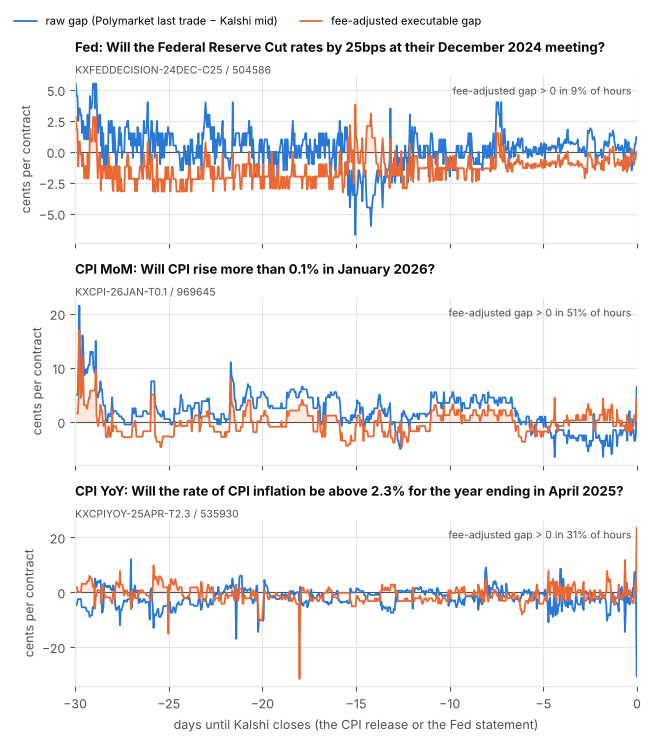

In [26]:
WINDOW_DAYS = 30
pair_info = pairs.set_index("pair_id")
settled_pair_ids = pair_info.index[pair_info["kalshi_result"].isin(["yes", "no"])
                                   & pair_info["poly_result"].isin(["yes", "no"])]
last_month = panel[(panel["hours_to_resolution"] <= WINDOW_DAYS * 24) & panel["pair_id"].isin(settled_pair_ids)]
candidates = last_month.groupby("pair_id").agg(topic=("topic", "first"), main_hours=("main", "sum"),
                                               mean_mid=("kalshi_mid", "mean")).reset_index()
candidates = candidates[candidates["mean_mid"].between(0.2, 0.8)]
examples = (candidates.sort_values(["main_hours", "pair_id"], ascending=[False, True])
                      .groupby("topic").head(1).set_index("topic").reindex(TOPICS)["pair_id"])
print(examples.to_string())

figure, axes = plt.subplots(3, 1, figsize=(6.5, 7.2), sharex=True)
for axis, (topic, pair_id) in zip(axes, examples.items()):
    rows = last_month[last_month["pair_id"] == pair_id]
    days = -rows["hours_to_resolution"].to_numpy() / 24
    raw = np.where(rows["main"], 100 * rows["raw_gap"], np.nan)
    net = np.where(rows["main"], 100 * rows["exec_net"], np.nan)
    axis.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
    axis.fill_between(days, 0, net, where=net > 0, color=ORANGE, alpha=0.15, linewidth=0)
    axis.plot(days, raw, color=BLUE, linewidth=1.3, label="raw gap (Polymarket last trade − Kalshi mid)")
    axis.plot(days, net, color=ORANGE, linewidth=1.3, label="fee-adjusted executable gap")
    axis.text(0, 1.0, pair_id, transform=axis.transAxes, ha="left", va="bottom", fontsize=7.5,
              color=TEXT_SECONDARY)
    axis.set_title(f"{topic}: {pair_info.loc[pair_id, 'kalshi_title']}\n", loc="left")
    axis.set_ylabel("cents per contract")
    share = (rows.loc[rows["main"], "exec_net"] > 0).mean()
    axis.text(0.99, 0.95, f"fee-adjusted gap > 0 in {share:.0%} of hours", transform=axis.transAxes,
              ha="right", va="top", fontsize=7.5, color=TEXT_SECONDARY)
axes[-1].set_xlabel("days until Kalshi closes (the CPI release or the Fed statement)")
axes[-1].set_xlim(-WINDOW_DAYS, 0)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="upper left", ncol=2, bbox_to_anchor=(0.0, 1.03), fontsize=8)
figure.tight_layout()
save(figure, "gap_over_time_examples")
plt.show()

**Figure 2: distribution of the gaps**, all main-sample pair-hours, in bins of
half a cent. Gaps beyond ±10 cents are left out of the picture (the subtitle
gives their share) but not out of the statistics.

Saved figures/gap_histogram.png and .pdf


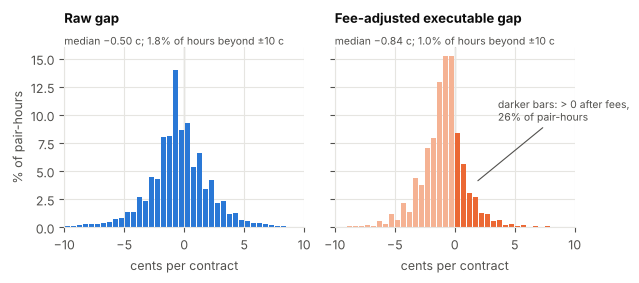

In [27]:
LIMIT = 10                                     # cents
# Bin edges just above each half cent: a gap of exactly 0 falls in the bar left of 0 ("not positive").
bins = np.arange(-LIMIT, LIMIT + 0.5, 0.5) + 1e-9
figure, axes = plt.subplots(1, 2, figsize=(6.5, 2.9), sharey=True)
for axis, column, title in [(axes[0], "raw_gap", "Raw gap"), (axes[1], "exec_net", "Fee-adjusted executable gap")]:
    cents = 100 * main[column]
    weights = np.full(len(cents), 100 / len(cents))         # bar heights in % of pair-hours
    heights, edges = np.histogram(cents, bins=bins, weights=weights)
    centres = (edges[:-1] + edges[1:]) / 2
    if column == "raw_gap":
        colours = [BLUE] * len(centres)
    else:   # profitable hours in full orange, the rest in a lighter step of the same hue
        colours = [ORANGE if centre > 0 else "#f5b293" for centre in centres]
    axis.bar(centres, heights, width=0.41, color=colours)
    axis.axvline(0, color=TEXT_SECONDARY, linewidth=0.8, zorder=0)
    outside = (cents.abs() > LIMIT).mean()
    axis.set_title(f"{title}\n", loc="left")
    axis.text(0, 1.0, f"median {cents.median():.2f} c; {outside:.1%} of hours beyond ±{LIMIT} c".replace("-", "−"),
              transform=axis.transAxes, fontsize=7.5, color=TEXT_SECONDARY, va="bottom")
    axis.set_xlabel("cents per contract")
    axis.set_xlim(-LIMIT, LIMIT)
axes[0].set_ylabel("% of pair-hours")
positive = (main["exec_net"] > 0).mean()
axes[1].annotate(f"darker bars: > 0 after fees,\n{positive:.0%} of pair-hours", xy=(1.75, 4.0), xytext=(3.6, 9.5),
                 fontsize=7.5, color=TEXT_SECONDARY,
                 arrowprops={"arrowstyle": "-", "color": TEXT_SECONDARY, "linewidth": 0.8})
figure.tight_layout()
save(figure, "gap_histogram")
plt.show()

**Figure 3: distribution of the half-lives** of part 4, one panel per topic,
in bins of one hour. Half-lives above 24 hours (and infinite ones) are put in
the last bar, marked ">24".

Saved figures/half_life_distribution.png and .pdf


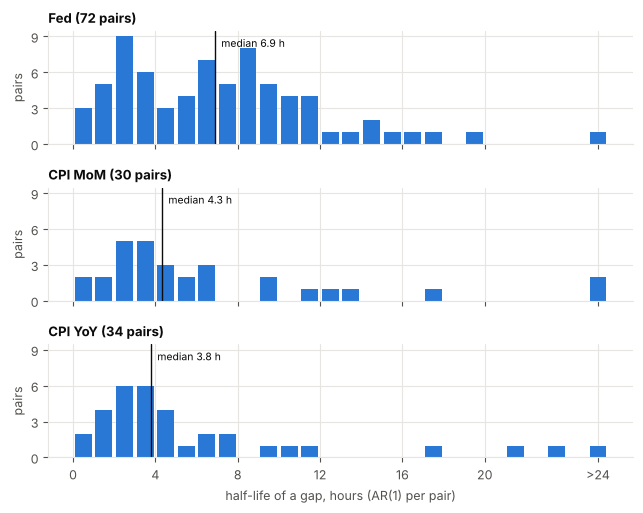

In [28]:
CAP = 24
figure, axes = plt.subplots(3, 1, figsize=(6.5, 5.2), sharex=True, sharey=True)
for axis, topic in zip(axes, TOPICS):
    lives = persistence.loc[persistence["topic"] == topic, "half_life"]
    # Half-lives above 24 h (and infinite ones) go into one overflow bar at 25-26 h.
    axis.hist(np.where(lives > CAP, CAP + 1.5, lives), bins=np.arange(0, CAP + 3, 1), color=BLUE, rwidth=0.82)
    axis.yaxis.set_major_locator(plt.MaxNLocator(nbins=4, integer=True))
    median = lives.median()
    axis.axvline(median, color=TEXT, linewidth=1)
    axis.text(median + 0.3, 0.95, f"median {median:.1f} h", transform=axis.get_xaxis_transform(),
              va="top", fontsize=7.5, color=TEXT)
    axis.set_title(f"{topic} ({len(lives)} pairs)", loc="left")
    axis.set_ylabel("pairs")
axes[-1].set_xticks(list(range(0, CAP, 4)) + [CAP + 1.5])
axes[-1].set_xticklabels([str(hour) for hour in range(0, CAP, 4)] + [f">{CAP}"])
axes[-1].set_xlabel("half-life of a gap, hours (AR(1) per pair)")
figure.tight_layout()
save(figure, "half_life_distribution")
plt.show()

### The results table: `docs/results.md`

The cell below writes the main tables of this notebook to `docs/results.md`,
with the choices and limitations, so the numbers can be quoted without
re-running the notebook. Re-running the notebook rewrites the file.

In [29]:
# The limitations, also shown as the last cell of this notebook
LIMITATIONS = r'''## Limitations

1. **Polymarket's executable price is estimated.** There is no historical
   Polymarket order book, only trades. The ask is the last trade + half a
   spread of 0.5 cents, taken from one order-book snapshot (4 November 2026).
   Thin CPI markets probably had wider spreads. Choosing the better of two
   directions also picks up whichever error looks profitable. The
   fee-adjusted gap is therefore an **upper bound**, and the sensitivity table
   shows how much it depends on the spread.
2. **No size.** Kalshi's candles have the best quotes but not the number of
   contracts at them, so we cannot say how much could have been traded.
3. **Hourly timing.** Kalshi's quote is the one at the end of the hour;
   Polymarket's last trade can be from any time in the previous 24 hours.
   Moves within the hour, and leads of a few minutes, are invisible.
4. **Odd single trades.** A few tiny Polymarket trades far from the market
   ("fat fingers", the first trades of a new market) create gaps of 50 cents or
   more. Medians, shares and a capped regression limit their influence, but
   they remain in the data.
5. **Selection on the outcome.** The 155 verified pairs were checked using
   their realised settlements, so pairs that paid differently were removed
   *after the fact*. Parts 1-6 therefore understate the resolution risk a
   trader faced at the time; part 7 adds those pairs back.
6. **Fees.** Kalshi's formula (0.07 × P × (1 − P), multiplier 1) is assumed to
   hold over the whole sample: Kalshi's fee-change history, which only starts
   in October 2025, has no change for these series. Polymarket's current fee
   schedule is assumed to apply from 30 March 2026. Fees are before rounding.
   Not included: maker rebates, deposit and withdrawal costs, and the interest
   the locked-up capital could have earned elsewhere.
7. **Persistence and price discovery.** The AR(1) assumes one constant speed
   of adjustment per pair. Bid-ask bounce makes gaps look less persistent;
   stale prices make them look more persistent. Granger tests compare a
   *quote* (Kalshi's mid) with a *trade* (Polymarket), find leads only at the
   hourly frequency, and give about 5% false positives per direction.
8. **Associations, not causes.** The regression shows which conditions go
   together with large gaps; busy hours are also hours with news.
9. **Few divergences.** Part 7 rests on 3 divergent pairs (two from the same
   faulty Polymarket event), so the divergence rate is imprecise; it uses
   Polymarket's own price series, whose exact definition the API does not give.
'''


from scipy import stats

def cell_text(value, digits):
    # One table cell as text: numbers rounded, missing values as a dash.
    if isinstance(value, (float, np.floating)):
        if np.isnan(value):
            return "–"
        if np.isinf(value):
            return "∞"
        return f"{value:,.{digits}f}"
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    return str(value)

COUNT_WORDS = ["pairs", "pair-hours", "no result"]   # columns with these words hold whole numbers

def markdown_table(table, digits=3):
    # A DataFrame as a Markdown table (index as the first column). A "|" inside a
    # cell is escaped, so it cannot split the table.
    table = table.copy()
    if isinstance(table.columns, pd.MultiIndex):
        table.columns = [" ".join(str(level) for level in column if str(level)) for column in table.columns]
    def escape(text):
        return str(text).replace("|", "\\|")
    index_name = table.index.name or ""
    index = [" / ".join(map(str, label)) if isinstance(label, tuple) else str(label) for label in table.index]
    lines = ["| " + " | ".join(escape(name) for name in [index_name] + list(table.columns)) + " |",
             "|" + "---|" * (len(table.columns) + 1)]
    for label, (_, row) in zip(index, table.iterrows()):
        cells = []
        for column, value in row.items():
            is_count = any(word in str(column) for word in COUNT_WORDS) and isinstance(value, (float, np.floating))
            cells.append(cell_text(int(value), digits) if is_count and np.isfinite(value) else cell_text(value, digits))
        lines.append("| " + " | ".join(escape(text) for text in [label] + cells) + " |")
    return "\n".join(lines)

def percent(table, columns):
    # Shares (0.25) as percentages (25.0%) for the chosen columns.
    table = table.copy()
    for column in columns:
        table[column] = [f"{100 * value:.1f}%" if pd.notna(value) else "–" for value in table[column]]
    return table

divergences, settled_count = int(settled["paid_differently"].sum()), len(settled)
low, high = stats.beta.ppf([0.025, 0.975], [divergences, divergences + 1], [settled_count - divergences + 1, settled_count - divergences])
pooled = RESULTS["pooled_ar1"]
breakeven = RESULTS["break_even"]
coverage_table = RESULTS["coverage"].drop(columns=["first_hour", "last_hour"]).rename(columns={
    "pair_hours": "pair-hours", "kalshi_bid_and_ask": "Kalshi bid and ask",
    "poly_price_at_most_24h_old": "Polymarket price ≤ 24 h old", "both": "both (main sample)",
    "under 1 h": "Polymarket price < 1 h old", "over 24 h (left out)": "Polymarket price > 24 h old"})
coverage_table = percent(coverage_table, coverage_table.columns[2:])
time_share_table = RESULTS["by_time_share"].rename_axis("time to resolution")
time_share_table = percent(time_share_table, TOPICS + ["all"])
sensitivity_table = percent(RESULTS["sensitivity"], RESULTS["sensitivity"].columns)
half_life_table = percent(RESULTS["half_lives"], ["share under 1 h", "share over 24 h"])
granger_table = percent(RESULTS["granger"], LEAD_ORDER)
granger_robustness_table = percent(RESULTS["granger_robustness"].drop(columns="no result"), LEAD_ORDER)
strategy_table = RESULTS["strategy"].rename_axis("")

# Key findings, written from the numbers above (so they always match the tables).
topic_rows = RESULTS["by_topic"]
fresh_row = RESULTS["half_life_robustness"].loc["fresh Polymarket prices only (< 1 h)"]
main_fit = fits["(1) main"]
traded_all = RESULTS["strategy"].loc["all traded"]
diverged_with_gap = int(traded["paid_differently"].sum())   # divergent pairs with a positive gap at the last point
KEY_FINDINGS = f'''## Key findings

1. **Profitable-looking hours are common but tiny.** After both fees, the
   executable-style gap is positive in {topic_rows.loc['all', 'share net > 0']:.0%} of
   the {len(main):,} main-sample pair-hours (Fed {topic_rows.loc['Fed', 'share net > 0']:.0%},
   CPI MoM {topic_rows.loc['CPI MoM', 'share net > 0']:.0%}, CPI YoY {topic_rows.loc['CPI YoY', 'share net > 0']:.0%}),
   with a median of {topic_rows.loc['all', 'median net when > 0 (c)']:.2f} cents per contract.
   The share depends mostly on Polymarket's unobserved spread: from
   {RESULTS['sensitivity'].iloc[-1, 0]:.0%} (no spread) to {RESULTS['sensitivity'].iloc[-1, -1]:.0%} (half spread 1 cent).
2. **Gaps close within hours.** The median half-life of a gap is
   {RESULTS['half_lives'].loc['all', 'median half-life (h)']:.1f} hours
   ({fresh_row[('median half-life (h)', 'all')]:.1f} hours with fresh Polymarket prices only).
3. **Gaps are smaller near prices of 0 or 1 and larger in CPI markets**
   ({main_fit.params['distance from 0.5 (cents)']:.3f} cents per cent of distance from 0.5;
   CPI MoM +{main_fit.params['CPI MoM']:.2f} and CPI YoY +{main_fit.params['CPI YoY']:.2f} cents compared with the Fed).
   More Polymarket volume goes with smaller gaps once outliers are capped.
4. **In Fed markets Kalshi tends to move first:** Kalshi leads in
   {RESULTS['granger'].loc['Fed', 'Kalshi leads']:.0%} of the Fed pairs, Polymarket in
   {RESULTS['granger'].loc['Fed', 'Polymarket leads']:.0%} (Granger tests, hourly).
5. **Resolution risk eats the profit.** {divergences} of {settled_count} settled pairs paid
   differently, and {diverged_with_gap} of them showed a positive fee-adjusted gap at the last
   moment both venues had prices. Trading every settled pair with a positive gap at that
   moment would have earned ${traded_all['realised profit ($)']:.2f} instead of the
   ${traded_all['expected profit, sum of gaps ($)']:.2f} the gaps promised ({int(traded_all['pairs'])} contracts). Covering
   such losses needs about {breakeven['needed_cents']:.1f} cents per normal trade, more
   than the typical positive gap.
'''
display(Markdown(KEY_FINDINGS))

sections = [
f'''# Results: historical price gaps between Kalshi and Polymarket

Made by `notebooks/01_historical_gaps.ipynb` from the data in `data/processed/`
(155 verified pairs, November 2024 to 4 November 2026; for part 7 all 177
settled candidate pairs). Re-running the notebook rewrites this file. All
times UTC; gaps in cents per contract (one contract pays $1).

{KEY_FINDINGS}
## Main choices

* **Grid:** one row per pair and hour (`bar_end`), from the first hour with a
  price on both venues to the last full hour before Kalshi's close (open pairs:
  until the Kalshi download, {DATA_END:%Y-%m-%d %H:%M} UTC).
* **Kalshi:** the last hourly candle carried forward without a time limit; an
  empty bid or ask stays empty; mid = (bid + ask) / 2.
* **Polymarket:** the latest trade of either token in Kalshi YES terms (using
  the pair's side), carried forward with its age; prices older than 24 hours are
  left out (main sample: Kalshi mid and a Polymarket price at most 24 h old,
  {len(main):,} pair-hours, {main["pair_id"].nunique()} pairs).
* **Raw gap** = Polymarket last trade − Kalshi mid.
* **Executable-style gap** = the better of the two directions: 1 − Kalshi ask (or
  1 − bid for NO) − Polymarket last trade ± half spread, minus both taker fees
  (`src/arb.py`, in force at each hour; Polymarket charges nothing before
  2026-03-30). **Half spread: {100 * HALF_SPREAD:.1f} cents**, half the median
  spread ({100 * TYPICAL_SPREAD:.0f} cent) of the {len(open_spreads)} open
  paired Polymarket order books of 2026-11-04.
* Cross-check against Polymarket's own price series: correlation
  {RESULTS["cross_check"].iloc[0]["correlation"]:.3f}, median difference
  {RESULTS["cross_check"].iloc[0]["median |difference| (cents)"]:.2f} cents.
''',
"## 1. Coverage\n\nShares of pair-hours.\n\n" + markdown_table(coverage_table),
"## 2-3. How often and how large\n\nMain sample. *net* = fee-adjusted executable gap; (c) = cents.\n\n"
+ markdown_table(percent(RESULTS["by_topic"], ["share net > 0", "share net > 1 c", "median pair's share net > 0",
                                                "median annualised when > 0"]), 2),
"### Share of pair-hours with a positive fee-adjusted gap, by time to resolution\n\n"
+ markdown_table(time_share_table),
"### Before / after Polymarket's fees, and by price level\n\n"
+ markdown_table(percent(RESULTS["cuts"], ["share net > 0", "share net > 1 c", "median pair's share net > 0",
                                           "median annualised when > 0"]), 2),
"### Distribution of gaps (cents, percentiles over pair-hours)\n\n" + markdown_table(RESULTS["distribution"], 2),
"### Sensitivity: share of hours with a positive fee-adjusted gap\n\n"
"Rows: maximum age of the Polymarket price. Columns: the assumed half spread.\n\n"
+ markdown_table(sensitivity_table),
"## 4. Persistence (AR(1) per pair)\n\n"
f"Pairs with at least {MIN_HOUR_PAIRS} pairs of neighbouring hours. Pooled AR(1) with pair fixed effects: "
f"rho = {pooled['rho']:.3f} (s.e. {pooled['se']:.3f}, clustered by pair), half-life {pooled['half_life']:.1f} hours.\n\n"
+ markdown_table(half_life_table, 2) + "\n\nRobustness (median across pairs):\n\n"
+ markdown_table(RESULTS["half_life_robustness"], 2),
"## 5. Determinants of the absolute gap\n\n"
"OLS; dependent variable |raw gap| in cents; standard errors clustered by pair in brackets; "
"\\* p < 0.1, \\*\\* p < 0.05, \\*\\*\\* p < 0.01.\n\n"
+ markdown_table(RESULTS["regression"].replace({r"\*": r"\\*"}, regex=True)),
"## 6. Price discovery (Granger causality, per pair)\n\n"
f"Share of tested pairs in each class at the 5% level, {LAGS} hourly lags, HC1-robust F-tests.\n\n"
+ markdown_table(granger_table) + "\n\nRobustness (all tested pairs):\n\n"
+ markdown_table(granger_robustness_table),
"## 7. Resolution risk (177 settled candidate pairs)\n\n"
f"{divergences} of {settled_count} pairs paid differently ({divergences / settled_count:.1%}; "
f"95% confidence interval {low:.1%} to {high:.1%}).\n\n"
+ markdown_table(RESULTS["settlement_table"], 0)
+ "\n\nThe position with the better fee-adjusted gap at the last common price point "
"(Polymarket price history, settlement rows dropped):\n\n"
+ markdown_table(RESULTS["diverged_positions"], 4)
+ "\n\nA trader who enters every settled pair with a positive fee-adjusted gap at the last common point "
"(one contract each):\n\n" + markdown_table(strategy_table, 4)
+ f"\n\nBreak-even: if every divergence lost the stake (on average ${breakeven['typical_loss']:.2f}), "
f"each normal trade would have to earn {breakeven['needed_cents']:.2f} cents; the median positive "
f"fee-adjusted gap is {breakeven['typical_gain_cents']:.2f} cents.",
'''## Figures

* `figures/gap_over_time_examples.png` (and `.pdf`): raw and fee-adjusted gap in the last 30 days of one
  pair per topic.
* `figures/gap_histogram.png`: distribution of raw and fee-adjusted gaps.
* `figures/half_life_distribution.png`: half-lives of the gaps, per topic.
''',
LIMITATIONS,
]
results_path = DOCS / "results.md"
results_path.write_text("\n\n".join(sections) + "\n", encoding="utf-8")
print(f"Wrote {results_path.relative_to(PROJECT)} ({results_path.stat().st_size / 1000:.0f} kB)")

## Key findings

1. **Profitable-looking hours are common but tiny.** After both fees, the
   executable-style gap is positive in 26% of
   the 162,937 main-sample pair-hours (Fed 20%,
   CPI MoM 43%, CPI YoY 43%),
   with a median of 0.87 cents per contract.
   The share depends mostly on Polymarket's unobserved spread: from
   41% (no spread) to 17% (half spread 1 cent).
2. **Gaps close within hours.** The median half-life of a gap is
   5.3 hours
   (2.6 hours with fresh Polymarket prices only).
3. **Gaps are smaller near prices of 0 or 1 and larger in CPI markets**
   (-0.050 cents per cent of distance from 0.5;
   CPI MoM +1.06 and CPI YoY +1.61 cents compared with the Fed).
   More Polymarket volume goes with smaller gaps once outliers are capped.
4. **In Fed markets Kalshi tends to move first:** Kalshi leads in
   28% of the Fed pairs, Polymarket in
   13% (Granger tests, hourly).
5. **Resolution risk eats the profit.** 3 of 177 settled pairs paid
   differently, and 3 of them showed a positive fee-adjusted gap at the last
   moment both venues had prices. Trading every settled pair with a positive gap at that
   moment would have earned $0.25 instead of the
   $1.25 the gaps promised (32 contracts). Covering
   such losses needs about 1.3 cents per normal trade, more
   than the typical positive gap.


Wrote docs/results.md (14 kB)


## Limitations

The same list is written to `docs/results.md`.


1. **Polymarket's executable price is estimated.** There is no historical
   Polymarket order book, only trades. The ask is the last trade + half a
   spread of 0.5 cents, taken from one order-book snapshot (4 November 2026).
   Thin CPI markets probably had wider spreads. Choosing the better of two
   directions also picks up whichever error looks profitable. The
   fee-adjusted gap is therefore an **upper bound**, and the sensitivity table
   shows how much it depends on the spread.
2. **No size.** Kalshi's candles have the best quotes but not the number of
   contracts at them, so we cannot say how much could have been traded.
3. **Hourly timing.** Kalshi's quote is the one at the end of the hour;
   Polymarket's last trade can be from any time in the previous 24 hours.
   Moves within the hour, and leads of a few minutes, are invisible.
4. **Odd single trades.** A few tiny Polymarket trades far from the market
   ("fat fingers", the first trades of a new market) create gaps of 50 cents or
   more. Medians, shares and a capped regression limit their influence, but
   they remain in the data.
5. **Selection on the outcome.** The 155 verified pairs were checked using
   their realised settlements, so pairs that paid differently were removed
   *after the fact*. Parts 1-6 therefore understate the resolution risk a
   trader faced at the time; part 7 adds those pairs back.
6. **Fees.** Kalshi's formula (0.07 × P × (1 − P), multiplier 1) is assumed to
   hold over the whole sample: Kalshi's fee-change history, which only starts
   in October 2025, has no change for these series. Polymarket's current fee
   schedule is assumed to apply from 30 March 2026. Fees are before rounding.
   Not included: maker rebates, deposit and withdrawal costs, and the interest
   the locked-up capital could have earned elsewhere.
7. **Persistence and price discovery.** The AR(1) assumes one constant speed
   of adjustment per pair. Bid-ask bounce makes gaps look less persistent;
   stale prices make them look more persistent. Granger tests compare a
   *quote* (Kalshi's mid) with a *trade* (Polymarket), find leads only at the
   hourly frequency, and give about 5% false positives per direction.
8. **Associations, not causes.** The regression shows which conditions go
   together with large gaps; busy hours are also hours with news.
9. **Few divergences.** Part 7 rests on 3 divergent pairs (two from the same
   faulty Polymarket event), so the divergence rate is imprecise; it uses
   Polymarket's own price series, whose exact definition the API does not give.